# Imports

In [50]:
import kagglehub
import numpy as np
from tensorflow.keras.datasets import mnist
from sklearn.decomposition import PCA, KernelPCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from data.data_loader import load_blood_cells
from methods.bcgd_gauss_southwell import gs_bcgd
from methods.bcgd_randomized import randomized_bcgd
from methods.gradient_descent import gradient_descent
from methods.utils.accuracy import accuracy
from methods.utils.block_size import block_step_size
from methods.utils.gradient import MultiLogisticRegressionOracle, CachedMultiLogisticRegressionOracle
from methods.utils.results import accuracy_vs_CPU, distance_vs_iterations
from scipy.spatial.distance import pdist, squareform

rng = np.random.default_rng(seed=42) # Turnoff or modify if no seeding will be used.
MAX_ITER = 10000

# Data Loading

## Synthetic Data

In [38]:
n_categories = 50
n_features = 500
n_examples = 1000

syntetic_features = rng.random((n_examples, n_features))
X = rng.random((n_features, n_categories))
E = rng.random((n_examples, n_categories))

transformation = np.dot(syntetic_features,X) + E
syntetic_labels = np.argmax(transformation, axis= 1)

syntetic_test_features = rng.random((n_examples, n_features))
test_transformation = np.dot(syntetic_features,X) + E
syntetic_test_labels = np.argmax(test_transformation, axis= 1)

syntetic_data = {
    "n_categories": n_categories,
    "n_features": n_features,
    "train_features": syntetic_features,
    "train_labels": syntetic_labels,
    "test_features": syntetic_test_features,
    "test_labels": syntetic_test_labels,
    "tolerance": 1e-2,
}

## MNIST Dataset

In [39]:
n_components = 50
(mnist_features, mnist_labels), (mnist_features_test, mnist_labels_test) = mnist.load_data()

mnist_features = mnist_features.reshape((mnist_features.shape[0],-1))
mnist_features_test = mnist_features_test.reshape((mnist_features_test.shape[0],-1))

scaler = StandardScaler()
pca = PCA(n_components=n_components)

mnist_reduced_features = scaler.fit_transform(mnist_features)
mnist_reduced_features = pca.fit_transform(mnist_reduced_features)

mnist_reduced_features_test = scaler.transform(mnist_features_test)
mnist_reduced_features_test = pca.transform(mnist_reduced_features_test)

mnist_data = {
    "n_categories": 10,
    "n_features": n_components,
    "train_features": mnist_reduced_features,
    "train_labels": mnist_labels,
    "test_features": mnist_reduced_features_test,
    "test_labels": mnist_labels_test,
    "tolerance": 1e-2,
}

## Bloodcell Dataset

In [40]:
# run this cell only once to download the dataset, then comment it out
path = kagglehub.dataset_download("unclesamulus/blood-cells-image-dataset", output_dir="blood_cells_data")

In [41]:
blood_features, blood_labels, labels_names = load_blood_cells(dataset_dir=f"blood_cells_data/bloodcells_dataset")
blood_train_features, blood_test_features, blood_train_labels, blood_test_labels = train_test_split(blood_features, blood_labels, test_size=0.2, random_state=42)

In [33]:
n_components = 50

blood_train_features = blood_train_features.reshape((blood_train_features.shape[0], -1))
blood_test_features = blood_test_features.reshape((blood_test_features.shape[0], -1))

scaler_blood = StandardScaler()
pca_blood = PCA(n_components=n_components)

blood_train_scaled = scaler_blood.fit_transform(blood_train_features)
blood_test_scaled = scaler_blood.transform(blood_test_features)

blood_reduced_features = pca_blood.fit_transform(blood_train_scaled)
blood_test_reduced = pca_blood.transform(blood_test_scaled)

blood_data = {
    "n_categories": len(labels_names),
    "n_features": n_components,              
    "train_features": blood_reduced_features, 
    "train_labels": blood_train_labels,
    "test_features": blood_test_reduced,    
    "test_labels": blood_test_labels,
    "tolerance": 1e-3,
}


In [42]:

raw_cov = np.cov(blood_train_scaled[:, :100].T)
raw_off_diag_avg = np.mean(np.abs(raw_cov[np.triu_indices(100, k=1)]))

pca_cov = np.cov(blood_reduced_features.T)
pca_off_diag_avg = np.mean(np.abs(pca_cov[np.triu_indices(n_components, k=1)]))

print(f"Average off-diagonal covariance (Raw): {raw_off_diag_avg:.4f}")
print(f"Average off-diagonal covariance (PCA): {pca_off_diag_avg:.4f}") 

Average off-diagonal covariance (Raw): 0.1568
Average off-diagonal covariance (PCA): 0.0000


64


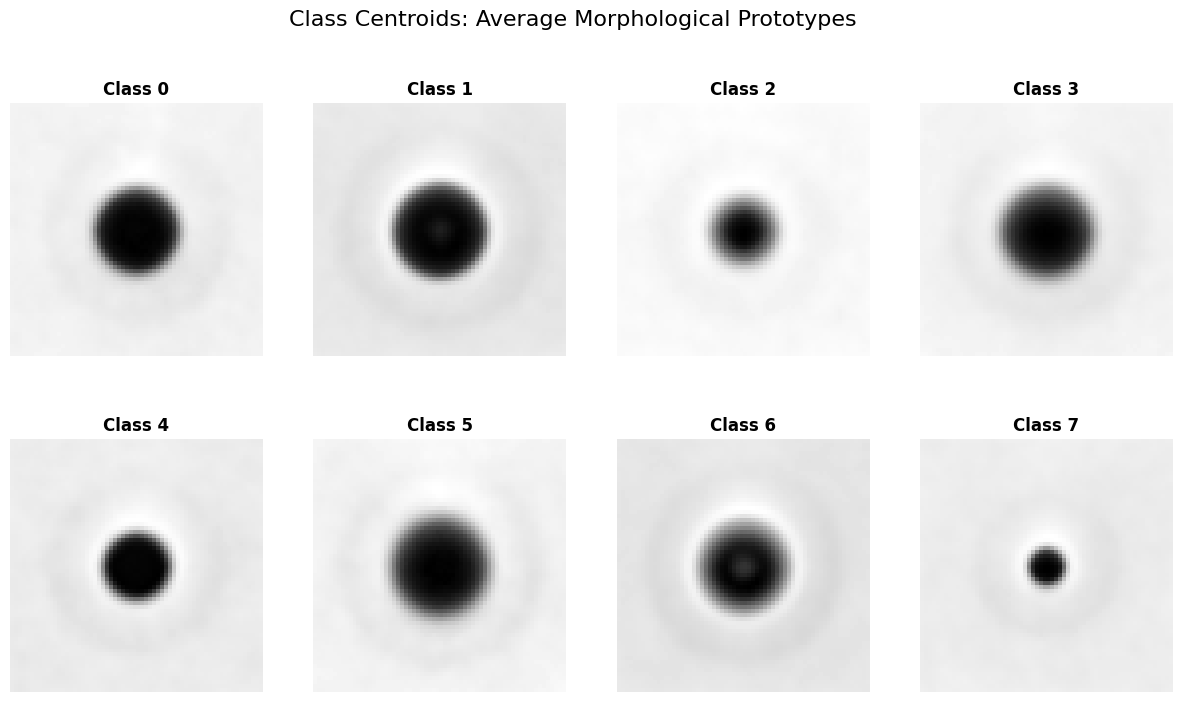

Avg dist between classes: 4.202517513879972


In [48]:
unique_labels = np.unique(blood_train_labels)
n_classes = len(unique_labels)
img_dim = int(np.sqrt(blood_train_features.shape[1]))
print(img_dim)

centroids = []
for label in unique_labels:
    mean = blood_train_features[blood_train_labels == label].mean(axis=0)
    centroids.append(mean)

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
fig.suptitle('Class Centroids: Average Morphological Prototypes', fontsize=16)

for i, ax in enumerate(axes.flat):
    if i < n_classes:
        img = centroids[i].reshape(img_dim, img_dim)
        
        ax.imshow(img, cmap='gray')
        ax.set_title(f'Class {i}', fontsize=12, fontweight='bold')
        ax.axis('off')

plt.show()

dist_matrix = squareform(pdist(centroids))
mean_dist = np.mean(dist_matrix[np.triu_indices(n_classes, k=1)])
print(f"Avg dist between classes: {mean_dist}")

In [ ]:
n_components=50
kpca_blood = KernelPCA(n_components=n_components, kernel='rbf', gamma=0.1, n_jobs=-1)
blood_reduced_kpca = kpca_blood.fit_transform(blood_train_scaled)
blood_test_reduced_kpca = kpca_blood.transform(blood_test_scaled)
blood_data_kpca = {
    "n_categories": len(labels_names),
    "n_features": n_components,
    "train_features": blood_reduced_kpca,
    "train_labels": blood_train_labels,
    "test_features": blood_test_reduced_kpca,
    "test_labels": blood_test_labels,
    "tolerance": 1e-3,
}

In [53]:
kpca = KernelPCA(n_components=n_components, kernel='rbf', gamma=0.1, n_jobs=-1)
blood_train_kpca = kpca.fit_transform(blood_train_scaled)
kpca_centroids = []
for label in unique_labels:
    mean_kpca = blood_train_kpca[blood_train_labels == label].mean(axis=0)
    kpca_centroids.append(mean_kpca)
kpca_dist_matrix = squareform(pdist(kpca_centroids))
kpca_mean_dist = np.mean(kpca_dist_matrix[np.triu_indices(n_classes, k=1)])
print(f"Raw Pixel Mean Distance: {mean_dist:.2f}")
print(f"Kernel PCA Mean Distance: {kpca_mean_dist:.2f}")

Raw Pixel Mean Distance: 4.20
Kernel PCA Mean Distance: 0.00


# Method Calls
This section is for implementing all the methods that will be used for generating graphs or any other types of solutions

In [17]:
dataset_name = "blood"
active_data = blood_data

#calculated step sizes
step_sizes = block_step_size(active_data["train_features"])
avg_step_size = np.average(step_sizes)

oracle = MultiLogisticRegressionOracle(active_data["train_features"], active_data["train_labels"], active_data["n_categories"])
cached_oracle = CachedMultiLogisticRegressionOracle(active_data["train_features"], active_data["train_labels"], active_data["n_categories"])

## Gradient Descent

In [18]:
gradient_descent_results = gradient_descent(
    np.zeros((active_data["n_features"], active_data["n_categories"])),
    oracle,
    avg_step_size/active_data["n_features"],
    tol=active_data["tolerance"],
    debug=True,
    max_iter=MAX_ITER,
)

Iteration 0: Loss = 27604.146431098074, sequential distance: 0.011715246506138284, Accuracy = 0.19600672858919038


In [ ]:
gradient_descent_results["test_accuracy"]

KeyError: 'test_accuracy'

In [20]:
gradient_descent_results["accuracies"] = [
    accuracy(oracle.predictors, oracle.predictions, x)
    for x in gradient_descent_results["history"]
]
gradient_descent_results["test_accuracy"] = accuracy(active_data["test_features"],active_data["test_labels"], gradient_descent_results["x_k"])

## BCGD Randomized

In [ ]:
randomized_bcgd_results = randomized_bcgd(
    np.zeros((active_data["n_features"], active_data["n_categories"])),
    oracle,
    step_sizes,
    tol=active_data["tolerance"],
    debug=True,
    max_iter=MAX_ITER,
)

iteration: 0, sequential distance: 0.17332699144490815, loss: 131654.91901458678
accuracy: 0.19383333333333333


In [21]:
randomized_bcgd_results["accuracies"] = [
    accuracy(oracle.predictors, oracle.predictions, x)
    for x in randomized_bcgd_results["history"]
]

randomized_bcgd_results["test_accuracy"] = accuracy(active_data["test_features"],active_data["test_labels"], randomized_bcgd_results["x_k"])

NameError: name 'randomized_bcgd_results' is not defined

## Gauss-Southwell BCGD

In [22]:
gs_bcgd_results = gs_bcgd(
    np.zeros((active_data["n_features"], active_data["n_categories"])),
    cached_oracle,
    step_sizes,
    tol=active_data["tolerance"],
    debug=True,
    max_iter=MAX_ITER,
)

iteration: 0, selected_block: 1120, sequential distance: 0.6698627211460485, loss: 27598.180487
accuracy: 19.60%
iteration: 500, selected_block: 83, sequential distance: 0.03452157043544275, loss: 14799.697335
accuracy: 65.09%
iteration: 1000, selected_block: 2017, sequential distance: 0.09223277521455125, loss: 13510.273343
accuracy: 67.27%
iteration: 1500, selected_block: 1591, sequential distance: 0.017645613982167314, loss: 12925.172223
accuracy: 68.34%
iteration: 2000, selected_block: 2676, sequential distance: 0.014195746332322345, loss: 12570.152863
accuracy: 69.10%
iteration: 2500, selected_block: 3851, sequential distance: 0.011349469001929863, loss: 12323.628417
accuracy: 69.62%
iteration: 3000, selected_block: 3411, sequential distance: 0.011064373387338544, loss: 12139.292518
accuracy: 70.15%
iteration: 3500, selected_block: 2200, sequential distance: 0.022330852194593503, loss: 11995.058000
accuracy: 70.41%
iteration: 4000, selected_block: 1633, sequential distance: 0.0205

KeyboardInterrupt: 

In [ ]:
gs_bcgd_results["accuracies"] = [
    accuracy(oracle.predictors, oracle.predictions, x)
    for x in gs_bcgd_results["history"]
]

gs_bcgd_results["test_accuracy"] = accuracy(active_data["test_features"],active_data["test_labels"], gs_bcgd_results["x_k"])

# Results

## Accuracy vs CPU Time

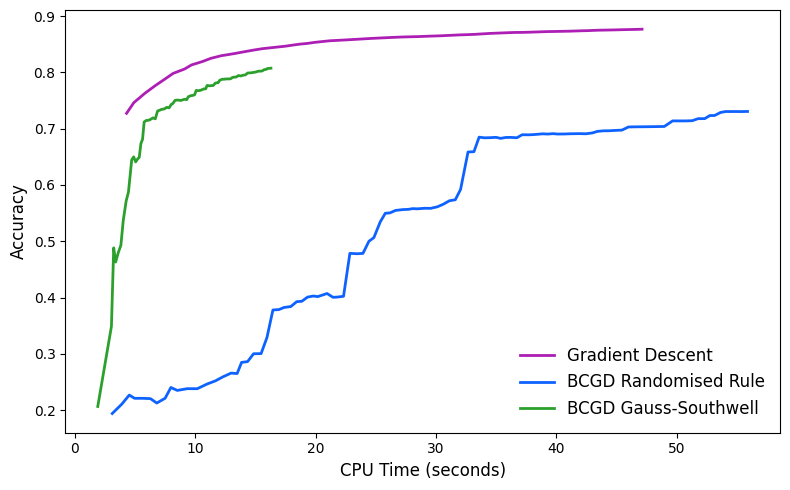

In [ ]:
plotting_data = {
    "Gradient Descent": (gradient_descent_results["times"], gradient_descent_results["accuracies"]),
    "BCGD Randomised Rule": (randomized_bcgd_results["times"], randomized_bcgd_results["accuracies"]),
    "BCGD Gauss-Southwell": (gs_bcgd_results["times"], gs_bcgd_results["accuracies"]),
}

accuracy_vs_CPU(plotting_data)

## Tabular Performance

In [ ]:
print(f"====== Results for {dataset_name} ========")
print(f"---- Gradient Descent ----")
print(f"Final Iteration: {gradient_descent_results['iterations']}")
print(f"Final Training Accuracy: {gradient_descent_results['accuracies'][-1]}")
print(f"Testing Accuracy: {gradient_descent_results['test_accuracy']}")
print(f"Total CPU time: {gradient_descent_results['times'][-1]} seconds")

print(f"---- Randomized BCGD ----")
print(f"Final Iteration: {randomized_bcgd_results['iterations']}")
print(f"Final Training Accuracy: {randomized_bcgd_results['accuracies'][-1]}")
print(f"Testing Accuracy: {randomized_bcgd_results['test_accuracy']}")
print(f"Total CPU time: {randomized_bcgd_results['times'][-1]} seconds")

print(f"---- GS BCGD ----")
print(f"Final Iteration: {gs_bcgd_results['iterations']}")
print(f"Final Training Accuracy: {gs_bcgd_results['accuracies'][-1]}")
print(f"Testing Accuracy: {gs_bcgd_results['test_accuracy']}")
print(f"Total CPU time: {gs_bcgd_results['times'][-1]} seconds")

====== Results for Synthetic ========
---- Gradient Descent ----
Final Iteration: 1999
Final Training Accuracy: 1.0
Testing Accuracy: 0.269
Total CPU time: 140.616575203 seconds
---- Randomized BCGD ----
Final Iteration: 1999
Final Training Accuracy: 0.809
Testing Accuracy: 0.317
Total CPU time: 108.61496927499999 seconds
---- GS BCGD ----
Final Iteration: 1999
Final Training Accuracy: 0.9
Testing Accuracy: 0.291
Total CPU time: 141.607135837 seconds


## Distance vs. Iterations

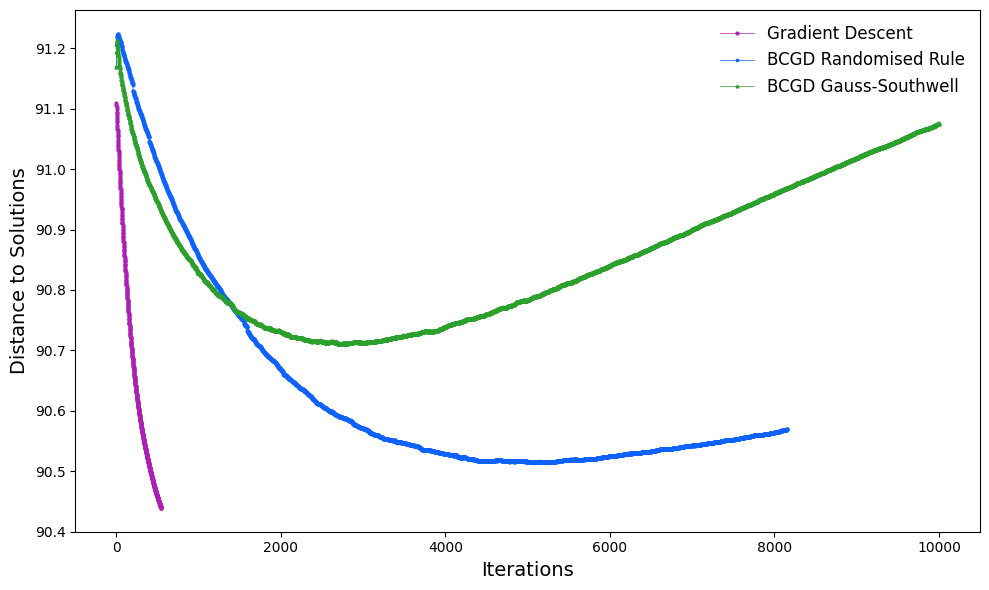

In [ ]:
distance_plot_data = {
    "Gradient Descent": [np.linalg.norm(x - gradient_descent_results["history"][-1])  for x in gradient_descent_results["history"]],
    "BCGD Randomised Rule": [np.linalg.norm(x - randomized_bcgd_results["history"][-1])  for x in randomized_bcgd_results["history"]],
    "BCGD Gauss-Southwell": [np.linalg.norm(x - gs_bcgd_results["history"][-1])  for x in gs_bcgd_results["history"]],
}

# distance_to_theoretical_plot_data = {
#     "Gradient Descent": [np.linalg.norm(x - X)  for x in gradient_descent_results["history"]],
#     "BCGD Randomised Rule": [np.linalg.norm(x - X)  for x in randomized_bcgd_results["history"]],
#     "BCGD Gauss-Southwell": [np.linalg.norm(x - X)  for x in gs_bcgd_results["history"]],
# }

distance_vs_iterations(distance_plot_data) 

## Algorithm Weardown

In [ ]:
def wear_down_algorithm(data, oracle, method, min_step_size, max_step_size, tol, max_iter, step_to_interval = False):
    x_k = np.zeros((data["n_features"], data["n_categories"]))
    results =[]
    step_sizes = np.exp(np.linspace(np.log(min_step_size), np.log(max_step_size), 50))
    
    for step_size in step_sizes:
        print(step_size)
        if step_to_interval:
            step_size = [step_size]*data["n_features"]
        algorithm_results = method(
            x_k,
            oracle,
            step_size,
            tol=tol,
            max_iter=max_iter,
        )
        history = np.array(algorithm_results["history"])
        if np.isnan(history).any():
            break
        else:
            results.append(algorithm_results["iterations"])

In [ ]:
import matplotlib.pyplot as plt

def plot_weardown(data):
    colors = ["#ad1fb4", "#0e62ff", "#2ca02c"] 
    fig, ax = plt.subplots(figsize=(10, 6))

    markers = ['o', 's', '^']
    linewidth = 0.5
    markersize = 2

    for i, (label, (iterations)) in enumerate(data.items()):
        ax.plot(
            list(range(len(iterations))),
            iterations,
            marker=markers[i % len(markers)],
            color=colors[i],
            linewidth=linewidth,
            markersize=markersize,
            label=label
        )

    ax.set_xlabel("Step Size", fontsize=14)
    ax.set_ylabel("Iterations", fontsize=14)

    ax.grid(False)
    
    ax.tick_params(colors='black')

    ax.legend(frameon=False, fontsize=12)

    plt.tight_layout()
    plt.show()

In [ ]:
gradient_descent_weardown_results = wear_down_algorithm(active_data, oracle, gradient_descent, 0.0001, 10, active_data["tolerance"], 200)
randomized_bcgd_weardown_results = wear_down_algorithm(active_data, oracle, randomized_bcgd, 0.0001, 10, active_data["tolerance"], 200, step_to_interval=True)
gs_bcgd_weardown_results = wear_down_algorithm(active_data, cached_oracle, gs_bcgd, 0.0001, 10, active_data["tolerance"], 200, step_to_interval=True)

wear_down_plot_data = {
    "Gradient Descent": gradient_descent_weardown_results,
    "BCGD Randomised Rule": randomized_bcgd_weardown_results,
    "BCGD Gauss-Southwell": gs_bcgd_weardown_results,
}

0.0001
0.0021387755102040816
0.004177551020408164
0.006216326530612245


/home/jjb_1/master/second_semester/optimization/assignment_optimization_2025_2026/methods/utils/gradient.py:28: RuntimeWarning: overflow encountered in exp
  transformed_entries = np.exp(np.dot(self.predictors, x)) # m x k
/home/jjb_1/master/second_semester/optimization/assignment_optimization_2025_2026/methods/utils/gradient.py:30: RuntimeWarning: invalid value encountered in divide
  softmax_entries = transformed_entries / summed_entries # m x k


0.0001
0.02050612244897959
0.04091224489795919
0.06131836734693878
0.08172448979591837
0.10213061224489796
0.12253673469387756
0.14294285714285712
0.16334897959183672
0.18375510204081633
0.2041612244897959
0.2245673469387755
0.2449734693877551
0.2653795918367347
0.28578571428571425
0.30619183673469386
0.32659795918367346
0.34700408163265306
0.36741020408163266
0.3878163265306122
0.4082224489795918
0.4286285714285714
0.449034693877551
0.4694408163265306
0.4898469387755102
0.5102530612244898
0.5306591836734694
0.551065306122449
0.5714714285714285
0.5918775510204082
0.6122836734693877
0.6326897959183674
0.6530959183673469
0.6735020408163265
0.6939081632653061
0.7143142857142857
0.7347204081632653
0.7551265306122449
0.7755326530612244
0.7959387755102041
0.8163448979591836
0.8367510204081633
0.8571571428571428
0.8775632653061224
0.897969387755102
0.9183755102040816
0.9387816326530612
0.9591877551020408
0.9795938775510205
1.0
0.0001
0.02050612244897959
0.04091224489795919
0.06131836734693878